In [4]:
import pandas as pd 
import numpy as np 
 
from sklearn.model_selection import train_test_split 
from sklearn.linear_model import LogisticRegression 
 
 
from sklearn.preprocessing import StandardScaler 
 
from sklearn.metrics import ( 
    confusion_matrix, 
    accuracy_score, 
    precision_score, 
    recall_score, 
    f1_score, 
    classification_report, 
    roc_auc_score, 
    roc_curve, 
    log_loss, 
    balanced_accuracy_score, 
    matthews_corrcoef 
)

In [5]:
data = { 
    'Transaction_ID': ['T1', 'T2', 'T3', 'T4', 'T5', 
                      'T6', 'T7', 'T8', 'T9', 'T10'], 
    'Amount': [200, 500, 900, 150, 1200, 
               300, 2000, 700, 1500, 1800], 
    'International': [0, 0, 1, 0, 1, 0, 1, 1, 1, 1], 
    'Failed_Attempts': [0, 1, 2, 0, 3, 1, 2, 1, 0, 3], 
    'Unusual_Time': [0, 0, 1, 0, 1, 0, 1, 1, 1, 1], 
    'Fraud': [0, 0, 1, 0, 1, 0, 1, 0, 0, 1] 
} 
 
df = pd.DataFrame(data) 
print(df) 

  Transaction_ID  Amount  International  Failed_Attempts  Unusual_Time  Fraud
0             T1     200              0                0             0      0
1             T2     500              0                1             0      0
2             T3     900              1                2             1      1
3             T4     150              0                0             0      0
4             T5    1200              1                3             1      1
5             T6     300              0                1             0      0
6             T7    2000              1                2             1      1
7             T8     700              1                1             1      0
8             T9    1500              1                0             1      0
9            T10    1800              1                3             1      1


In [6]:
df

,Transaction_ID,Amount,International,Failed_Attempts,Unusual_Time,Fraud
0,T1,200,0,0,0,0
1,T2,500,0,1,0,0
2,T3,900,1,2,1,1
3,T4,150,0,0,0,0
4,T5,1200,1,3,1,1
5,T6,300,0,1,0,0
6,T7,2000,1,2,1,1
7,T8,700,1,1,1,0
8,T9,1500,1,0,1,0
9,T10,1800,1,3,1,1


In [7]:
X = df.drop(columns=['Transaction_ID', 'Fraud']) 
y = df['Fraud'] 

In [8]:
X

,Amount,International,Failed_Attempts,Unusual_Time
0,200,0,0,0
1,500,0,1,0
2,900,1,2,1
3,150,0,0,0
4,1200,1,3,1
5,300,0,1,0
6,2000,1,2,1
7,700,1,1,1
8,1500,1,0,1
9,1800,1,3,1


In [9]:
y

0    0
1    0
2    1
3    0
4    1
5    0
6    1
7    0
8    0
9    1
Name: Fraud, dtype: int64

In [10]:
X_train, X_test, y_train, y_test = train_test_split( 
 
 
    X, 
    y, 
    test_size=0.30, 
    random_state=42, 
    stratify=y 
) 

In [11]:
scaler = StandardScaler() 
 
X_train_scaled = scaler.fit_transform(X_train) 
X_test_scaled = scaler.transform(X_test) 

In [12]:
model = LogisticRegression() 

In [13]:
model.fit(X_train_scaled, y_train) 

,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation <regularized-logistic-loss>`) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",0.0001
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneOnly used for `solver` == 'sag', 'saga' or 'liblinear' to shuffle thedata. It has no effect on the other solvers.See :term:`Glossary <random_state>` for details.",None
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following

In [14]:
y_train_pred = model.predict(X_train_scaled) 
y_test_pred = model.predict(X_test_scaled) 

In [15]:
y_train_prob = model.predict_proba(X_train_scaled)[:, 1] 
y_test_prob = model.predict_proba(X_test_scaled)[:, 1] 

In [16]:
y_train_prob

array([0.04268424, 0.86878537, 0.0440071 , 0.81867741, 0.77454206,
       0.34245288, 0.1087828 ])

In [17]:
print("Coefficients:", model.coef_) 
print("Intercept:", model.intercept_) 

Coefficients: [[0.45280078 0.39503382 1.00142599 0.39503382]]
Intercept: [-0.61607253]


ROC-AUC: 1.0


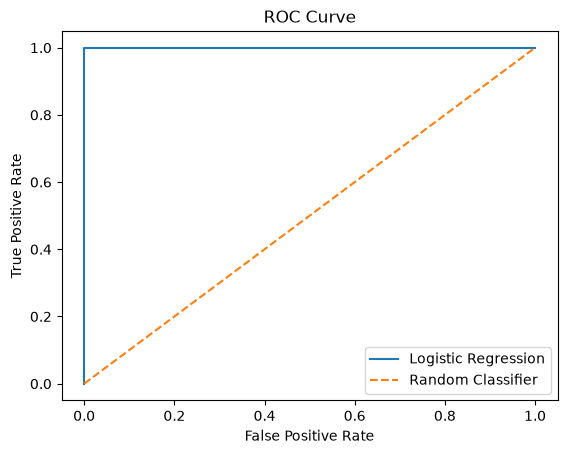

In [12]:
import matplotlib.pyplot as plt 
 
roc_auc = roc_auc_score(y_test, y_test_prob) 
print("ROC-AUC:", roc_auc) 
 
fpr, tpr, thresholds = roc_curve(y_test, y_test_prob) 
plt.plot(fpr, tpr, label='Logistic Regression') 
plt.plot([0, 1], [0, 1], linestyle='--', label='Random Classifier') 
plt.xlabel('False Positive Rate') 
plt.ylabel('True Positive Rate') 
plt.title('ROC Curve') 
plt.legend() 
plt.show()

In [18]:
print("TRAINING PERFORMANCE") 
print("Accuracy:", accuracy_score(y_train, y_train_pred)) 
print("Precision:", precision_score(y_train, y_train_pred, zero_division=0)) 
print("Recall:", recall_score(y_train, y_train_pred, zero_division=0)) 
print("F1 Score:", f1_score(y_train, y_train_pred, zero_division=0)) 
print("ROC-AUC:", roc_auc_score(y_train, y_train_prob)) 
print("Log Loss:", log_loss(y_train, y_train_prob)) 
print("Balanced Accuracy:", balanced_accuracy_score(y_train, y_train_pred)) 
print("MCC:", matthews_corrcoef(y_train, y_train_pred)) 
 
print("\nTESTING PERFORMANCE") 
print("Accuracy:", accuracy_score(y_test, y_test_pred)) 
print("Precision:", precision_score(y_test, y_test_pred, zero_division=0)) 
print("Recall:", recall_score(y_test, y_test_pred, zero_division=0)) 
print("F1 Score:", f1_score(y_test, y_test_pred, zero_division=0)) 
print("ROC-AUC:", roc_auc_score(y_test, y_test_prob)) 
print("Log Loss:", log_loss(y_test, y_test_prob)) 
print("Balanced Accuracy:", balanced_accuracy_score(y_test, y_test_pred)) 
print("MCC:", matthews_corrcoef(y_test, y_test_pred))

TRAINING PERFORMANCE
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
ROC-AUC: 1.0
Log Loss: 0.17417719881278446
Balanced Accuracy: 1.0
MCC: 1.0

TESTING PERFORMANCE
Accuracy: 1.0
Precision: 1.0
Recall: 1.0
F1 Score: 1.0
ROC-AUC: 1.0
Log Loss: 0.36184135314467164
Balanced Accuracy: 1.0
MCC: 1.0
